# SoloQ batch visualizer
One real 16.20 batch: masking grid, histogram, popularity.
Cells 1-2 each do one full shard scan (~16s each in a kernel).
`M` = champ+role masked, `r` = role given (10%), gray = visible.


In [1]:
import sys
from pathlib import Path
import torch
PROC_DIR = Path(r'E:\VSCode\code\lol draft analysis\data\solo queue\process matchdata')
MODEL_DIR = Path(r'E:\VSCode\code\lol draft analysis\model')
DATA_DIR = PROC_DIR.parent


In [2]:
sys.path.insert(0, str(PROC_DIR))
sys.path.insert(0, str(MODEL_DIR / 'tests'))
import pipeline as P
print('pipeline from', P.__file__)
from test_soloq_contract import validate_batch_dict
print('contract import ok')
PATCH = '16.20'
ROLE_NAMES = ['TOP', 'JGL', 'MID', 'ADC', 'SUP']
print('torch', torch.__version__)


pipeline from E:\VSCode\code\lol draft analysis\data\solo queue\process matchdata\pipeline.py
contract import ok
torch 2.4.1+cu118


In [3]:
# 1. Champion mapping (one full shard scan).
shards = P.list_shards()
print(f'{len(shards)} shards')
riot_to_idx = P.build_champ_mapping(shards, PATCH,
    save_path=PROC_DIR / 'champ_mapping.json')
idx_to_riot = {v: k for k, v in riot_to_idx.items()}
print(f'patch {PATCH}: {len(riot_to_idx)} champions, saved')


48 shards
patch 16.20: 173 champions, saved


In [4]:
# 2. Index kept drafts + popularity baseline (second scan).
indexed = P.scan_and_index(shards, riot_to_idx, PATCH)
tot = indexed['kept'] + indexed['skipped']
print('kept', indexed['kept'], 'skipped', indexed['skipped'])
base = P.compute_popularity_baseline(indexed['rows'],
    len(riot_to_idx))
tops = [(r, base['role_top'][r][0]) for r in range(5)]
print('top-1 per role (idx):', tops)


kept 209538 skipped 19317
top-1 per role (idx): [(0, 156), (1, 59), (2, 86), (3, 111), (4, 141)]


In [5]:
# 3. One real batch + contract validation.
from torch.utils.data import DataLoader
ds = P.SoloQDraftDataset(indexed['rows'],
    num_champs=len(riot_to_idx), seed=0)
loader = DataLoader(ds, batch_size=32, shuffle=False,
    collate_fn=P.soloq_collate)
batch = next(iter(loader))
validate_batch_dict(batch, allow_partial=False)
print('batch OK')


batch OK


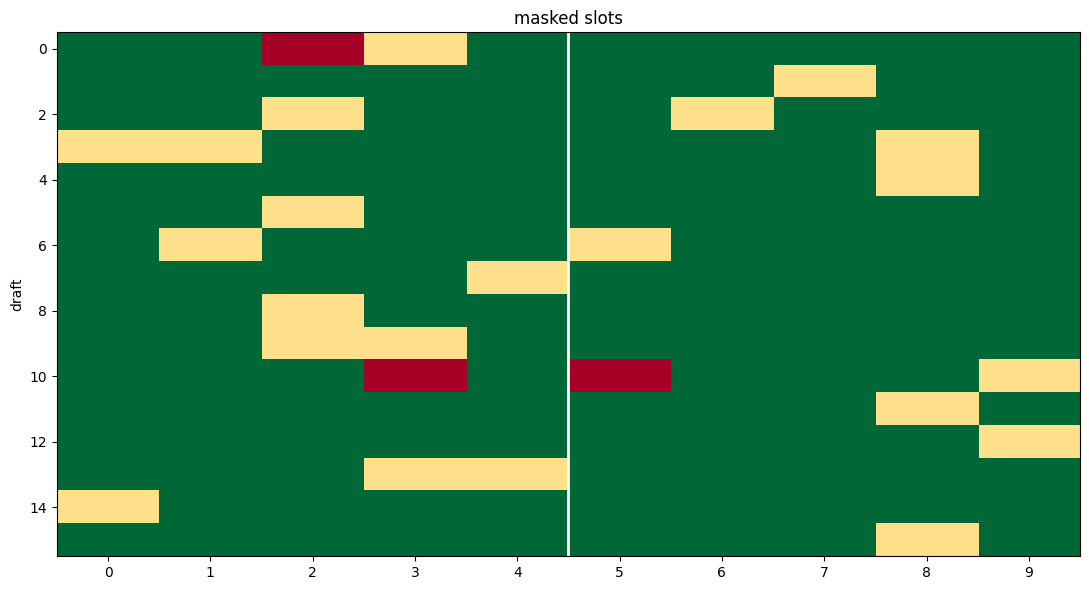

In [6]:
# 4. Masked-draft grid: 16 drafts x 10 slots.
import matplotlib.pyplot as plt
import numpy as np
B = 16
fig, ax = plt.subplots(figsize=(11, 6))
grid = np.zeros((B, 10))
grid[batch['is_masked'][:B].numpy()] = 1.0
grid[batch['role_masked'][:B].numpy()] = 0.6
ax.imshow(grid, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=1)
ax.set_xticks(range(10))
ax.set_ylabel('draft')
ax.axvline(4.5, color='white', lw=2)
ax.set_title('masked slots (red=M: champ+role hidden, yellow=r: role given)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='#d73027', edgecolor='white',
                         label='M: champ + role hidden (full mask)'),
                   Patch(facecolor='#fee08b', edgecolor='white',
                         label='r: champ hidden, role given (10%)'),
                   Patch(facecolor='#1a9850', edgecolor='white',
                         label='visible slot')],
          loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3,
          fontsize=8)
plt.tight_layout()
plt.show()


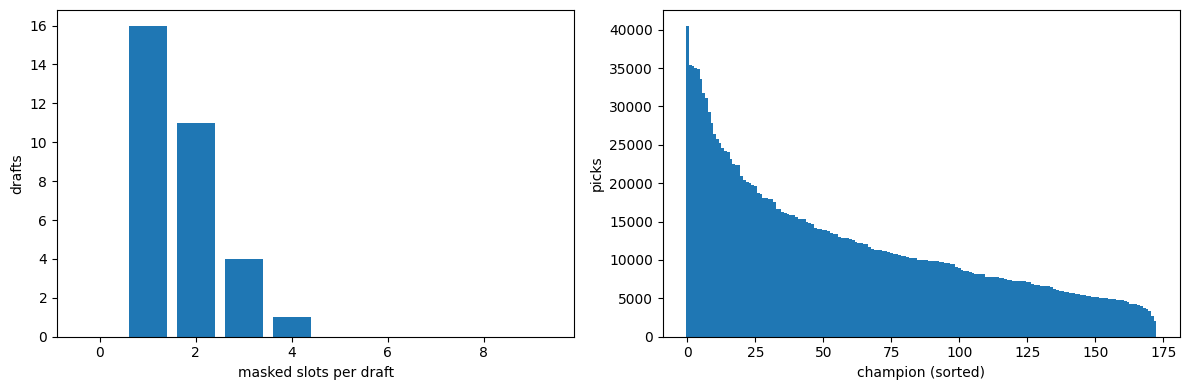

In [7]:
# 5. Mask histogram + popularity long tail.
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
masks = batch['is_masked'].sum(1).numpy()
a1.hist(masks, bins=range(0, 11), align='left', rwidth=0.8)
a1.set_xlabel('masked slots per draft')
a1.set_ylabel('drafts')
counts = base['global_counts'].numpy()
order = np.argsort(-counts)
a2.bar(range(len(counts)), counts[order], width=1.0)
a2.set_xlabel('champion (sorted)')
a2.set_ylabel('picks')
plt.tight_layout()
plt.show()


In [8]:
# 6. Model forward shapes on this batch.
import importlib.util
spec = importlib.util.spec_from_file_location('soloq_model',
    str(MODEL_DIR / 'soloq_model.py'))
sm = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sm)
model = sm.SoloQPretrainedModel(num_champs=len(riot_to_idx))
model.eval()
out = model(batch)
print('champ', tuple(out['champ_logits'].shape))
print('role', tuple(out['role_logits'].shape))


champ (32, 10, 173)
role (32, 10, 5)


In [9]:
# 7. Champion names (Data Dragon 16.20.1, cached to champ_names.json).
# Self-sufficient: re-establishes paths/imports if the kernel restarted.
import sys, os
from pathlib import Path as _Pl
_PROC = _Pl(r'E:\VSCode\code\lol draft analysis\data\solo queue\process matchdata')
_MOD = _Pl(r'E:\VSCode\code\lol draft analysis\model')
for _p in (str(_PROC), str(_MOD / 'tests')):
    assert os.path.exists(_p), _p
    if _p not in sys.path:
        sys.path.insert(0, _p)
import pipeline as P
riot_to_name = P.fetch_champ_names()
names = P.idx_names(riot_to_idx, riot_to_name)
print('example:', names[base['global_top'][0]], '| total:', len(names))
base = P.compute_popularity_baseline(indexed['rows'],
    len(riot_to_idx), names=names)
print('global top-5:', base['global_top_names'][:5])
print('global bottom-5:', base['global_top_names'][-5:])


example: Kai'Sa | total: 173
global top-5: ["Kai'Sa", 'Jhin', 'Sylas', 'Lee Sin', 'Yone']
global bottom-5: ['Kled', 'Ivern', 'Heimerdinger', 'Taric', 'Nilah']


In [12]:
# 8. Most/least popular 5 per role (name x picks).
RN = ['TOP', 'JGL', 'MID', 'ADC', 'SUP']
for r in range(5):
    top = [(base['role_top_names'][r][i],
             int(base['role_counts'][r, base['role_top'][r][i]]))
           for i in range(5)]
    bot = [(base['role_top_names'][r][-i],
             int(base['role_counts'][r, base['role_top'][r][-i]]))
           for i in range(1, 6)]
    print(RN[r], ' MOST PICKED', top)
    print(RN[r], 'LEAST PICKED', bot)


TOP  MOST PICKED [('Yone', 17495), ('Jayce', 15083), ('Malphite', 14826), ('Aatrox', 14024), ('Jax', 12801)]
TOP LEAST PICKED [('Renata Glasc', 1), ('Sona', 5), ('Nami', 6), ('Milio', 7), ('Yuumi', 7)]
JGL  MOST PICKED [('Lee Sin', 33663), ('Qiyana', 18462), ('Graves', 17493), ("Kha'Zix", 15941), ('Viego', 15755)]
JGL LEAST PICKED [('Ziggs', 0), ('Sona', 0), ('Smolder', 1), ('Senna', 1), ('Xerath', 1)]
MID  MOST PICKED [('Ahri', 18675), ('Viktor', 17795), ('Yasuo', 17752), ('Locke', 17165), ('Yone', 16460)]
MID LEAST PICKED [('Braum', 2), ('Yuumi', 8), ('Amumu', 8), ('Nilah', 9), ('Rell', 9)]
ADC  MOST PICKED [("Kai'Sa", 39254), ('Jhin', 34617), ('Jinx', 29213), ('Caitlyn', 27476), ('Yunara', 25021)]
ADC LEAST PICKED [('Rell', 0), ('Bard', 0), ("Bel'Veth", 0), ('Milio', 2), ('Evelynn', 2)]
SUP  MOST PICKED [('Thresh', 33498), ('Lulu', 30816), ('Nautilus', 22684), ('Nami', 20011), ('Karma', 17117)]
SUP LEAST PICKED [('Nilah', 2), ('Samira', 2), ('Sivir', 2), ('Aphelios', 5), ('Xayah', 5

In [11]:
# 9. Same forward as cell 6, predictions as names.
b = 0
mpos = batch['is_masked'][b].nonzero(as_tuple=True)[0].tolist()
for s in mpos[:3]:
    pr = out['champ_logits'][b, s].softmax(-1)
    t5 = pr.topk(5)
    tn = P.name_of(int(batch['champ_labels'][b, s]), names)
    ps = ' '.join(names[int(i)] + ':' + f'{float(p):.3f}'
                  for i, p in zip(t5.indices, t5.values))
    print('slot', s, ': truth', tn, '|', ps)


slot 2 : truth Katarina | Dr. Mundo:0.025 Twisted Fate:0.020 Sejuani:0.020 Sivir:0.020 Kayle:0.020
slot 3 : truth Zeri | Twisted Fate:0.023 Dr. Mundo:0.022 Sejuani:0.021 Kayle:0.019 Draven:0.019
